# Session 3: Correlation and Regression

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    pass  # numpy, pandas, scipy, statsmodels and matplotlib are preinstalled in Colab
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/03-inferential-statistical-analysis/code/'
    for f in []:
        if not os.path.exists(f):
            subprocess.run(['wget', '-q', base + f], check=False)
print('ready')

ready


## Example: `session-03_correlation.py`

In [2]:
"""
Session 3 · Example 1: Covariance and Pearson correlation, by hand and with SciPy
-------------------------------------------------------------------------------
Do students who study more hours score higher? We compute covariance and
Pearson's r step by step, test whether r is significantly different from 0,
and draw a 3-panel chart of positive, negative and 'no linear' relationships
(session-03_correlation.png), including a curved pattern where r is near 0
even though the variables are strongly related.

Run:  python session-03_correlation.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

hours = np.array([2, 3, 5, 1, 4, 6, 7, 3, 5, 8])            # weekly study hours
marks = np.array([55, 60, 70, 48, 66, 75, 82, 58, 68, 88])   # exam marks

# ---- Step by step -----------------------------------------------------------------
dx, dy = hours - hours.mean(), marks - marks.mean()
cov = (dx * dy).sum() / (len(hours) - 1)                       # sample covariance
r = cov / (hours.std(ddof=1) * marks.std(ddof=1))              # Pearson r = cov / (sx * sy)
print(f"mean hours = {hours.mean():.1f}, mean marks = {marks.mean():.1f}")
print(f"sum of cross-products = {(dx * dy).sum():.1f}")
print(f"covariance  = {cov:.3f}    (np.cov gives {np.cov(hours, marks)[0, 1]:.3f})")
print(f"Pearson r   = {r:.4f}   (r^2 = {r * r:.4f}: {100 * r * r:.1f}% of the variation in marks is linearly explained)")

# ---- Library + significance test --------------------------------------------------
res = stats.pearsonr(hours, marks)
t = r * np.sqrt((len(hours) - 2) / (1 - r ** 2))               # t statistic with n-2 df
print(f"scipy: r = {res.statistic:.4f}, p-value = {res.pvalue:.2e}; by hand t = {t:.2f} on {len(hours) - 2} df")

# ---- Covariance depends on units, correlation does not ----------------------------
minutes = hours * 60
print(f"\nStudy time in MINUTES: covariance = {np.cov(minutes, marks)[0, 1]:.1f} (60x bigger), "
      f"r = {np.corrcoef(minutes, marks)[0, 1]:.4f} (unchanged)")

# ---- Correlation matrix of several variables --------------------------------------
sleep = np.array([8, 7, 6, 9, 7, 6, 5, 8, 6, 5])               # hours of sleep
phone = np.array([5, 4, 3, 6, 3, 2, 1, 4, 3, 1])               # hours on phone per day
M = np.corrcoef([hours, marks, sleep, phone])
names = ["hours", "marks", "sleep", "phone"]
print("\nCorrelation matrix")
print(" " * 7 + "".join(f"{n:>8}" for n in names))
for n, row in zip(names, M):
    print(f"{n:<7}" + "".join(f"{v:>8.2f}" for v in row))

# ---- A strong but NON-linear relationship: r misses it ----------------------------
x = np.linspace(-3, 3, 25)
y = x ** 2
print(f"\ny = x^2 on [-3, 3]: Pearson r = {np.corrcoef(x, y)[0, 1]:.3f}  <- 'no LINEAR relationship', not 'no relationship'")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].scatter(hours, marks, color="#FF6B1A"); axes[0].set_title(f"Hours vs marks: r = {r:.2f}")
axes[1].scatter(phone, marks, color="#A78BFA"); axes[1].set_title(f"Phone vs marks: r = {np.corrcoef(phone, marks)[0, 1]:.2f}")
axes[2].scatter(x, y, color="#F43F5E"); axes[2].set_title("y = x squared: r = 0.00")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("session-03_correlation.png", dpi=100)
print("Saved chart: session-03_correlation.png")

mean hours = 4.4, mean marks = 67.0
sum of cross-products = 246.0
covariance  = 27.333    (np.cov gives 27.333)
Pearson r   = 0.9953   (r^2 = 0.9905: 99.1% of the variation in marks is linearly explained)
scipy: r = 0.9953, p-value = 2.21e-09; by hand t = 28.93 on 8 df

Study time in MINUTES: covariance = 1640.0 (60x bigger), r = 0.9953 (unchanged)

Correlation matrix
          hours   marks   sleep   phone
hours      1.00    1.00   -0.96   -0.98
marks      1.00    1.00   -0.96   -0.98
sleep     -0.96   -0.96    1.00    0.95
phone     -0.98   -0.98    0.95    1.00

y = x^2 on [-3, 3]: Pearson r = 0.000  <- 'no LINEAR relationship', not 'no relationship'


Saved chart: session-03_correlation.png


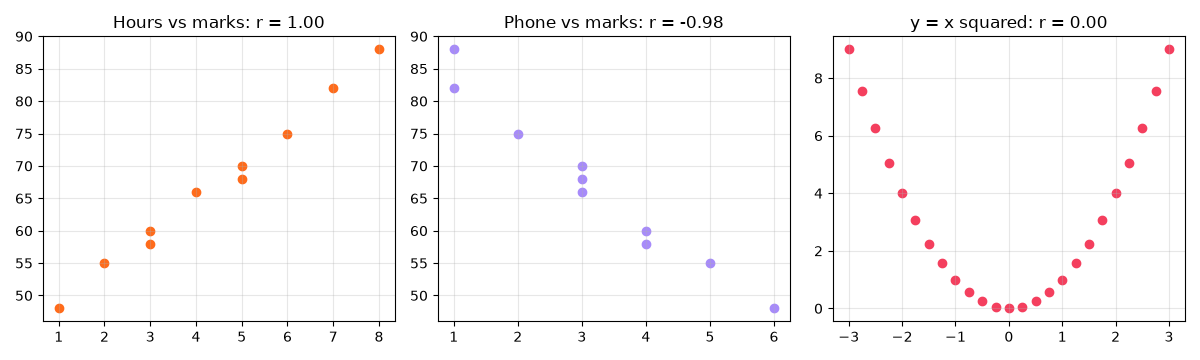

In [3]:
from IPython.display import Image, display
display(Image(filename='session-03_correlation.png'))  # chart saved by the cell above

## Example: `session-03_rank_correlation.py`

In [4]:
"""
Session 3 · Example 2: Rank correlation (Spearman and Kendall)
--------------------------------------------------------------
Two judges rank 8 entries in a university poster competition. Ranks are
ORDINAL, so Pearson's r is not appropriate; we use Spearman's rho:

      rho = 1 - 6 * sum(d^2) / (n (n^2 - 1))      (valid when there are no ties)

We also show that Spearman is robust to an outlier and measures any MONOTONIC
relationship, and handle tied values with average ranks.

Run:  python session-03_rank_correlation.py
"""
import numpy as np
from scipy import stats

entries = ["A", "B", "C", "D", "E", "F", "G", "H"]
judge1 = np.array([1, 2, 3, 4, 5, 6, 7, 8])
judge2 = np.array([2, 1, 4, 3, 6, 5, 8, 7])

d = judge1 - judge2
n = len(d)
rho = 1 - 6 * (d ** 2).sum() / (n * (n ** 2 - 1))
print("entry  J1  J2   d  d^2")
for e, a, b, di in zip(entries, judge1, judge2, d):
    print(f"  {e}    {a}   {b}  {di:+d}   {di * di}")
print(f"sum d^2 = {(d ** 2).sum()}  ->  rho = 1 - 6*{(d ** 2).sum()}/({n}*{n * n - 1}) = {rho:.4f}")
print(f"scipy spearmanr = {stats.spearmanr(judge1, judge2).statistic:.4f}, "
      f"kendalltau = {stats.kendalltau(judge1, judge2).statistic:.4f}")

# ---- Ties: give tied values the AVERAGE of the ranks they occupy -------------------
scores = np.array([70, 85, 85, 60, 90, 70, 75])
print("\nScores:", scores.tolist())
print("Average ranks:", stats.rankdata(scores).tolist(), " (the two 85s share ranks 5 and 6 -> 5.5)")

# ---- Robustness and monotonic relationships ---------------------------------------
income = np.array([30, 35, 40, 45, 50, 55, 60, 65, 70, 900])   # one billionaire-style outlier
spend = np.array([20, 24, 27, 30, 33, 35, 38, 41, 43, 60])
print(f"\nWith an outlier: Pearson r = {stats.pearsonr(income, spend).statistic:.3f}, "
      f"Spearman rho = {stats.spearmanr(income, spend).statistic:.3f}")
x = np.arange(1, 11)
y = np.exp(x / 2)                                              # monotonic but curved
print(f"Exponential curve: Pearson r = {stats.pearsonr(x, y).statistic:.3f}, "
      f"Spearman rho = {stats.spearmanr(x, y).statistic:.3f} (perfectly monotonic)")

entry  J1  J2   d  d^2
  A    1   2  -1   1
  B    2   1  +1   1
  C    3   4  -1   1
  D    4   3  +1   1
  E    5   6  -1   1
  F    6   5  +1   1
  G    7   8  -1   1
  H    8   7  +1   1
sum d^2 = 8  ->  rho = 1 - 6*8/(8*63) = 0.9048
scipy spearmanr = 0.9048, kendalltau = 0.7143

Scores: [70, 85, 85, 60, 90, 70, 75]
Average ranks: [2.5, 5.5, 5.5, 1.0, 7.0, 2.5, 4.0]  (the two 85s share ranks 5 and 6 -> 5.5)

With an outlier: Pearson r = 0.796, Spearman rho = 1.000
Exponential curve: Pearson r = 0.865, Spearman rho = 1.000 (perfectly monotonic)


## Example: `session-03_simple_regression.py`

In [5]:
"""
Session 3 · Example 3: Simple linear regression with least squares
-----------------------------------------------------------------
Fit  marks = b0 + b1 * hours  using the closed-form least-squares formulas

      b1 = sum((x - x_bar)(y - y_bar)) / sum((x - x_bar)^2)
      b0 = y_bar - b1 * x_bar

then compute fitted values, residuals, SST = SSR + SSE, R^2, the standard
error of the slope, a 95% CI for the slope, and predictions. Compare with
scipy.stats.linregress and save a fit + residual chart (session-03_simple_regression.png).

Run:  python session-03_simple_regression.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

x = np.array([2, 3, 5, 1, 4, 6, 7, 3, 5, 8], dtype=float)       # study hours
y = np.array([55, 60, 70, 48, 66, 75, 82, 58, 68, 88], dtype=float)
n = len(x)

# ---- 1. Coefficients ----------------------------------------------------------------
Sxy = ((x - x.mean()) * (y - y.mean())).sum()
Sxx = ((x - x.mean()) ** 2).sum()
b1 = Sxy / Sxx
b0 = y.mean() - b1 * x.mean()
print(f"Sxy = {Sxy:.2f}, Sxx = {Sxx:.2f}")
print(f"Fitted line: marks = {b0:.3f} + {b1:.3f} * hours")
print(f"Meaning: each extra weekly study hour is associated with {b1:.2f} more marks.")

# ---- 2. Goodness of fit -------------------------------------------------------------
y_hat = b0 + b1 * x
resid = y - y_hat
SST = ((y - y.mean()) ** 2).sum()          # total variation
SSR = ((y_hat - y.mean()) ** 2).sum()      # explained by the line
SSE = (resid ** 2).sum()                   # left over (errors)
print(f"\nSST = {SST:.2f} = SSR {SSR:.2f} + SSE {SSE:.2f}")
print(f"R^2 = SSR/SST = {SSR / SST:.4f}")
s = np.sqrt(SSE / (n - 2))                 # residual standard error
se_b1 = s / np.sqrt(Sxx)
t_crit = stats.t.ppf(0.975, n - 2)
print(f"Residual standard error = {s:.3f} marks")
print(f"SE(b1) = {se_b1:.4f}; 95% CI for slope = [{b1 - t_crit * se_b1:.3f}, {b1 + t_crit * se_b1:.3f}]")
print(f"Residuals sum to {resid.sum():.1e} (always ~0 for least squares)")

# ---- 3. Check with SciPy ------------------------------------------------------------
lr = stats.linregress(x, y)
print(f"\nlinregress: slope {lr.slope:.3f}, intercept {lr.intercept:.3f}, r {lr.rvalue:.4f}, "
      f"p {lr.pvalue:.2e}, stderr {lr.stderr:.4f}")

# ---- 4. Prediction (and the danger of extrapolation) --------------------------------
for h in [4.5, 9, 20]:
    pred = b0 + b1 * h
    note = "" if h <= 8 else "  <- extrapolation: outside the observed 1-8 h, treat with caution"
    if pred > 100:
        note = "  <- IMPOSSIBLE: marks cannot exceed 100; the straight line does not hold out here"
    print(f"Predicted marks for {h:>4} h: {b0 + b1 * h:6.1f}{note}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.scatter(x, y, color="#FF6B1A", zorder=3)
xs = np.linspace(0, 9, 50)
a1.plot(xs, b0 + b1 * xs, color="#0A0716", label=f"y = {b0:.1f} + {b1:.2f}x")
for xi, yi, yh in zip(x, y, y_hat):
    a1.plot([xi, xi], [yi, yh], color="#A78BFA", lw=1)          # residual segments
a1.set_xlabel("study hours"); a1.set_ylabel("marks"); a1.set_title("Least-squares line"); a1.legend()
a2.scatter(y_hat, resid, color="#F43F5E"); a2.axhline(0, color="grey", ls="--")
a2.set_xlabel("fitted value"); a2.set_ylabel("residual"); a2.set_title("Residuals: no pattern = good")
for ax in (a1, a2):
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("session-03_simple_regression.png", dpi=100)
print("Saved chart: session-03_simple_regression.png")

Sxy = 246.00, Sxx = 44.40
Fitted line: marks = 42.622 + 5.541 * hours
Meaning: each extra weekly study hour is associated with 5.54 more marks.

SST = 1376.00 = SSR 1362.97 + SSE 13.03
R^2 = SSR/SST = 0.9905
Residual standard error = 1.276 marks
SE(b1) = 0.1915; 95% CI for slope = [5.099, 5.982]
Residuals sum to 2.1e-14 (always ~0 for least squares)

linregress: slope 5.541, intercept 42.622, r 0.9953, p 2.21e-09, stderr 0.1915
Predicted marks for  4.5 h:   67.6
Predicted marks for    9 h:   92.5  <- extrapolation: outside the observed 1-8 h, treat with caution
Predicted marks for   20 h:  153.4  <- IMPOSSIBLE: marks cannot exceed 100; the straight line does not hold out here
Saved chart: session-03_simple_regression.png


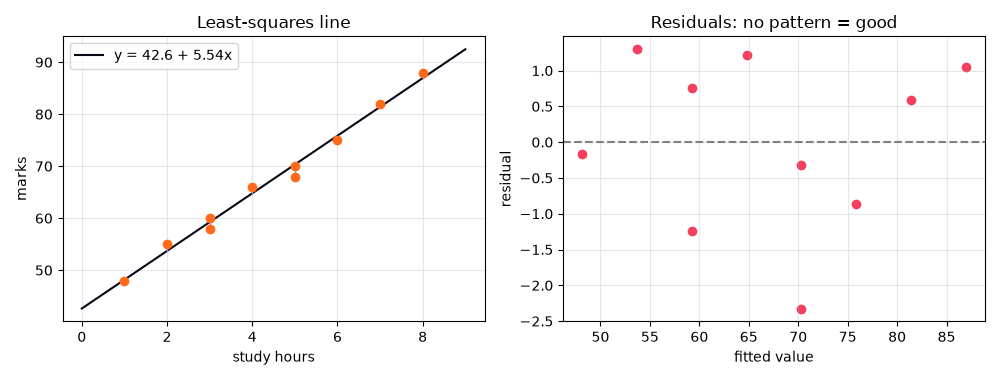

In [6]:
from IPython.display import Image, display
display(Image(filename='session-03_simple_regression.png'))  # chart saved by the cell above

## Example: `session-03_regression_types.py`

In [7]:
"""
Session 3 · Example 4: Types of regression - multiple, polynomial and logistic
-----------------------------------------------------------------------------
1. Multiple linear regression with statsmodels (two predictors, full summary numbers)
2. Polynomial regression: a curved relationship fitted with numpy.polyfit
3. Logistic regression: predicting a yes/no outcome (pass/fail) as a probability

Run:  python session-03_regression_types.py
"""
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

rng = np.random.default_rng(3)

# ---- 1. Multiple regression: marks ~ hours + attendance ----------------------------
df = pd.DataFrame({
    "hours":      [2, 3, 5, 1, 4, 6, 7, 3, 5, 8, 2, 6, 4, 7, 1],
    "attendance": [70, 80, 85, 60, 75, 90, 95, 65, 88, 98, 85, 70, 92, 80, 75],
})
df["marks"] = (20 + 4.5 * df.hours + 0.35 * df.attendance + rng.normal(0, 2.5, len(df))).round(1)
model = smf.ols("marks ~ hours + attendance", data=df).fit()
print("1) Multiple regression: marks ~ hours + attendance")
print(model.params.round(3).to_string())
print(f"R^2 = {model.rsquared:.3f}, adjusted R^2 = {model.rsquared_adj:.3f}, F p-value = {model.f_pvalue:.2e}")
print("p-values:", model.pvalues.round(4).to_dict())
new = pd.DataFrame({"hours": [5], "attendance": [90]})
print(f"Prediction for 5 h and 90% attendance: {model.predict(new).iloc[0]:.1f} marks")

# ---- 2. Polynomial regression: fuel use vs speed is U-shaped ------------------------
speed = np.array([20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120])
litres = np.array([9.8, 8.1, 6.9, 6.2, 5.9, 6.0, 6.4, 7.1, 8.0, 9.2, 10.6])  # litres per 100 km
lin = np.polyfit(speed, litres, 1)
quad = np.polyfit(speed, litres, 2)
def r2(y, yh):
    return 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print("\n2) Polynomial regression: fuel use vs speed")
print(f"straight line R^2 = {r2(litres, np.polyval(lin, speed)):.3f}")
print(f"quadratic      R^2 = {r2(litres, np.polyval(quad, speed)):.3f}  "
      f"(litres = {quad[0]:.5f}v^2 {quad[1]:+.4f}v {quad[2]:+.2f})")
print(f"most efficient speed = {-quad[1] / (2 * quad[0]):.0f} km/h (vertex of the parabola)")

# ---- 3. Logistic regression: P(pass) from study hours -------------------------------
hours = np.array([0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7])
passed = np.array([0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])
logit = sm.Logit(passed, sm.add_constant(hours)).fit(disp=False)
b0, b1 = logit.params
print("\n3) Logistic regression: P(pass) = 1 / (1 + exp(-(b0 + b1*hours)))")
print(f"b0 = {b0:.3f}, b1 = {b1:.3f}; odds of passing multiply by {np.exp(b1):.2f} per extra hour")
for h in [1, 3, 5]:
    print(f"  P(pass | {h} h) = {1 / (1 + np.exp(-(b0 + b1 * h))):.3f}")
print(f"  50% chance at {-b0 / b1:.2f} hours")

1) Multiple regression: marks ~ hours + attendance
Intercept     17.846
hours          4.745
attendance     0.357
R^2 = 0.938, adjusted R^2 = 0.927, F p-value = 5.96e-08
p-values: {'Intercept': 0.0488, 'hours': 0.0, 'attendance': 0.0103}
Prediction for 5 h and 90% attendance: 73.7 marks

2) Polynomial regression: fuel use vs speed
straight line R^2 = 0.068
quadratic      R^2 = 0.989  (litres = 0.00168v^2 -0.2229v +13.33)
most efficient speed = 66 km/h (vertex of the parabola)

3) Logistic regression: P(pass) = 1 / (1 + exp(-(b0 + b1*hours)))
b0 = -4.705, b1 = 1.451; odds of passing multiply by 4.27 per extra hour
  P(pass | 1 h) = 0.037
  P(pass | 3 h) = 0.413
  P(pass | 5 h) = 0.927
  50% chance at 3.24 hours


## Example: `session-03_problem_rent_model.py`

In [8]:
"""
Session 3 · Real-life problem: is this flat's rent fair?
-------------------------------------------------------
PROBLEM
A property website has 24 listings of two-to-four room flats in one Karachi
area (rent in thousand PKR per month, covered area in square feet, rooms,
age of the building in years). A friend is offered a 1,150 sq ft, 3-room flat in
an 8-year-old building at 95k per month. Build a model and answer:
  1. Which variable is most strongly correlated with rent (Pearson and Spearman)?
  2. Fit rent ~ area (simple) and rent ~ area + rooms + age (multiple). Which is better?
  3. Interpret each coefficient in plain words.
  4. Predict the fair rent with a 95% prediction interval. Is 95k fair?

The listings are generated from a known formula plus noise so the script is
self-contained and reproducible (seed 21).
Run:  python session-03_problem_rent_model.py
"""
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

rng = np.random.default_rng(21)
n = 24
area = rng.integers(750, 1800, n)
rooms = np.clip((area / 450).round().astype(int) + rng.integers(-1, 2, n), 2, 4)
age = rng.integers(1, 25, n)
rent = (15 + 0.055 * area + 4 * rooms - 0.9 * age + rng.normal(0, 5, n)).round(1)
df = pd.DataFrame({"area": area, "rooms": rooms, "age": age, "rent": rent})
print(df.describe().round(1).loc[["mean", "std", "min", "max"]].to_string())

# 1. Correlations with rent
print("\n1) Correlation with rent")
print(pd.DataFrame({"pearson": df.corr()["rent"], "spearman": df.corr(method="spearman")["rent"]})
      .drop("rent").round(3).to_string())

# 2. Two models
simple = smf.ols("rent ~ area", df).fit()
multi = smf.ols("rent ~ area + rooms + age", df).fit()
print(f"\n2) simple  : R^2 {simple.rsquared:.3f}, adj R^2 {simple.rsquared_adj:.3f}, "
      f"residual SE {np.sqrt(simple.mse_resid):.2f}k")
print(f"   multiple: R^2 {multi.rsquared:.3f}, adj R^2 {multi.rsquared_adj:.3f}, "
      f"residual SE {np.sqrt(multi.mse_resid):.2f}k")

# 3. Interpretation
p = multi.params
print("\n3) Coefficients (multiple model)")
print(f"   +100 sq ft  -> {100 * p['area']:+.2f}k rent, other things equal")
print(f"   +1 room     -> {p['rooms']:+.2f}k   (p = {multi.pvalues['rooms']:.2g})")
print(f"   +1 year old -> {p['age']:+.2f}k   (p = {multi.pvalues['age']:.2g})")

# 4. Prediction interval for the offered flat
flat = pd.DataFrame({"area": [1150], "rooms": [3], "age": [8]})
pred = multi.get_prediction(flat).summary_frame(alpha=0.05).iloc[0]
print(f"\n4) Fair rent estimate: {pred['mean']:.1f}k "
      f"(95% prediction interval {pred['obs_ci_lower']:.1f}k to {pred['obs_ci_upper']:.1f}k)")
offer = 95
verdict = "ABOVE the plausible range: negotiate" if offer > pred["obs_ci_upper"] else \
          "within the plausible range" if offer >= pred["obs_ci_lower"] else "a bargain"
print(f"   Offer of {offer}k is {verdict}.")

        area  rooms   age   rent
mean  1349.1    3.0  12.2   89.8
std    292.3    0.9   6.2   19.6
min    843.0    2.0   2.0   62.2
max   1779.0    4.0  22.0  122.8

1) Correlation with rent
       pearson  spearman
area     0.924     0.931
rooms    0.539     0.531
age     -0.466    -0.464

2) simple  : R^2 0.853, adj R^2 0.847, residual SE 7.68k
   multiple: R^2 0.960, adj R^2 0.954, residual SE 4.18k

3) Coefficients (multiple model)
   +100 sq ft  -> +4.77k rent, other things equal
   +1 room     -> +5.84k   (p = 6.7e-05)
   +1 year old -> -1.06k   (p = 1.2e-06)

4) Fair rent estimate: 84.5k (95% prediction interval 75.3k to 93.7k)
   Offer of 95k is ABOVE the plausible range: negotiate.


## Example: `session-03_project_sales_forecaster.py`

In [9]:
"""
Session 3 · Mini project: advertising-spend sales forecaster
-----------------------------------------------------------
A small online clothing brand logged 18 months of advertising spend on two
channels (social media and search ads, thousand PKR) and monthly sales
(lakh PKR). Build a reusable forecaster that:
  * implements multiple linear regression from scratch with the NORMAL EQUATION
        beta = (X^T X)^(-1) X^T y
  * reports coefficients, R^2, adjusted R^2 and RMSE
  * checks itself against numpy.linalg.lstsq
  * uses a train/test split (first 14 months train, last 4 test) to measure
    honest out-of-sample error
  * answers a budget question: where should the next 10k of ads go?
and saves an actual-vs-predicted chart: session-03_project_sales_forecaster.png

Run:  python session-03_project_sales_forecaster.py
"""
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


class LinearRegressionScratch:
    """Ordinary least squares with an intercept, solved by the normal equation."""

    def fit(self, X, y):
        X1 = np.column_stack([np.ones(len(X)), X])          # add the intercept column
        self.beta = np.linalg.solve(X1.T @ X1, X1.T @ y)    # solve() is safer than inv()
        self.n, self.k = X.shape
        resid = y - X1 @ self.beta
        self.r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
        self.adj_r2 = 1 - (1 - self.r2) * (self.n - 1) / (self.n - self.k - 1)
        return self

    def predict(self, X):
        return np.column_stack([np.ones(len(X)), X]) @ self.beta


social = np.array([20, 25, 30, 22, 35, 40, 28, 45, 50, 38, 55, 60, 42, 48, 65, 58, 70, 62], dtype=float)
search = np.array([10, 12, 15, 18, 14, 20, 25, 16, 22, 30, 18, 24, 35, 28, 26, 38, 30, 40], dtype=float)
noise = np.array([0.8, -0.5, 0.3, -0.9, 0.6, -0.2, 0.4, -0.7, 0.9, -0.3, 0.2, -0.6, 0.5, -0.4, 0.7, -0.8, 0.1, 0.3])
sales = 12 + 0.30 * social + 0.55 * search + noise            # the 'true' process, unknown to the model
X = np.column_stack([social, search])

# ---- Fit on all data and verify against numpy ------------------------------------
m = LinearRegressionScratch().fit(X, sales)
ref, *_ = np.linalg.lstsq(np.column_stack([np.ones(len(X)), X]), sales, rcond=None)
print("Coefficients (intercept, social, search)")
print("  scratch:", np.round(m.beta, 4))
print("  lstsq  :", np.round(ref, 4), "-> match:", np.allclose(m.beta, ref))
print(f"  R^2 = {m.r2:.4f}, adjusted R^2 = {m.adj_r2:.4f}")

# ---- Honest evaluation on unseen months -------------------------------------------
train, test = slice(0, 14), slice(14, 18)
mt = LinearRegressionScratch().fit(X[train], sales[train])
pred = mt.predict(X[test])
rmse = np.sqrt(np.mean((sales[test] - pred) ** 2))
mape = np.mean(np.abs((sales[test] - pred) / sales[test])) * 100
print("\nTrain on months 1-14, test on 15-18")
for mo, a, p in zip(range(15, 19), sales[test], pred):
    print(f"  month {mo}: actual {a:6.2f}  predicted {p:6.2f}  error {a - p:+.2f}")
print(f"  test RMSE = {rmse:.3f} lakh, MAPE = {mape:.2f}%")

# ---- Budget question --------------------------------------------------------------
b_social, b_search = m.beta[1], m.beta[2]
print(f"\nNext 10k on social adds about {10 * b_social:.2f} lakh; on search about {10 * b_search:.2f} lakh.")
print("Recommendation:", "search ads" if b_search > b_social else "social media",
      "(within the observed spending range only - returns usually diminish at higher spend).")

fig, ax = plt.subplots(figsize=(8, 3.8))
months = np.arange(1, 19)
ax.plot(months, sales, "o-", color="#FF6B1A", label="actual")
ax.plot(months[train], mt.predict(X[train]), "s--", color="#A78BFA", label="fitted (train)")
ax.plot(months[test], pred, "D--", color="#F43F5E", label="forecast (test)")
ax.axvspan(14.5, 18.5, color="#FCD34D", alpha=0.25)
ax.set_xlabel("month"); ax.set_ylabel("sales (lakh PKR)"); ax.set_title("Sales: actual vs model")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("session-03_project_sales_forecaster.png", dpi=100)
print("Saved chart: session-03_project_sales_forecaster.png")

Coefficients (intercept, social, search)
  scratch: [12.0638  0.3042  0.5404]
  lstsq  : [12.0638  0.3042  0.5404] -> match: True
  R^2 = 0.9955, adjusted R^2 = 0.9949

Train on months 1-14, test on 15-18
  month 15: actual  46.50  predicted  45.70  error +0.80
  month 16: actual  49.50  predicted  50.22  error -0.72
  month 17: actual  49.60  predicted  49.38  error +0.22
  month 18: actual  52.90  predicted  52.51  error +0.39
  test RMSE = 0.584 lakh, MAPE = 1.09%

Next 10k on social adds about 3.04 lakh; on search about 5.40 lakh.
Recommendation: search ads (within the observed spending range only - returns usually diminish at higher spend).
Saved chart: session-03_project_sales_forecaster.png


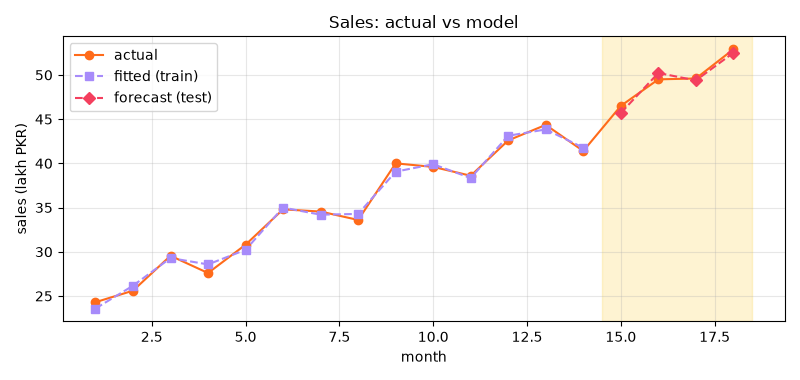

In [10]:
from IPython.display import Image, display
display(Image(filename='session-03_project_sales_forecaster.png'))  # chart saved by the cell above